In [10]:
from dotenv import load_dotenv
load_dotenv()


True

In [11]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_groq import ChatGroq
from langchain_community.vectorstores import InMemoryVectorStore
from langchain_huggingface import HuggingFaceEmbeddings

from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field


In [12]:
loader = PyPDFLoader("da.pdf")
docs = loader.load()

splitter = RecursiveCharacterTextSplitter(chunk_size = 1000,chunk_overlap=200)
splitted_docs = splitter.split_documents(docs)

embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")
vector_store = InMemoryVectorStore.from_documents(
    documents = splitted_docs,
    embedding=embeddings
)

c:\Users\ubais\Downloads\Gen AI\Day-8\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1820.58it/s]


In [13]:
llm = ChatGroq(model="openai/gpt-oss-20b")


In [14]:
class RagState(BaseModel):
    question:str =Field(description="User Question")
    documents:list = []
    context : str = Field(description="Context Data for user question", default="")
    answer:str = Field(description="Final Answer ....", default="")

In [15]:
def retrieve_node(state:RagState) -> RagState:
    splitted_docs = vector_store.similarity_search(query=state.question)
    state.documents = splitted_docs
    return state


def create_context_node(state:RagState) -> RagState:
    context = ""
    for doc in state.documents:
        context += doc.page_content + "\n\n"

    state.context = context
    return state


def generate_response_node(state:RagState) -> RagState:
    prompt = f"""
         You are a assistant and provide the answer for user question based on the provided context.
        If you don't find the relevant answer, then just say 'I dont know.'.
        Context is: {state.context},
        Questions is: {state.question}
    """
    res = llm.invoke(prompt)
    state.answer = res.content
    return state
    

In [16]:
graph = StateGraph(RagState)

graph.add_node("retrieve_node", retrieve_node)
graph.add_node("create_context_node", create_context_node)
graph.add_node("generate_response_node", generate_response_node)

graph.add_edge(START, 'retrieve_node')
graph.add_edge("retrieve_node", "create_context_node")
graph.add_edge("create_context_node", "generate_response_node")
graph.add_edge("generate_response_node", END)


graph = graph.compile()

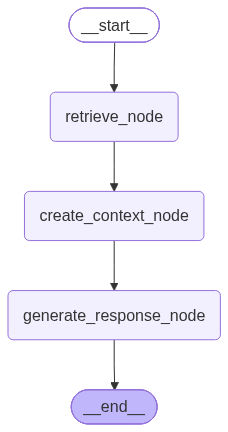

In [17]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [22]:
res = graph.invoke({"question":"What is the syllabus for Database  ?"})

In [23]:
print(res["answer"])

**Typical “Database Systems” Course Syllabus (≈ 15–18 weeks)**  

| Week | Topic | Key Sub‑topics |
|------|-------|----------------|
| 1 | **Introduction to Databases** | What is a database, DBMS vs file systems, history, use cases |
| 2 | **Relational Model** | Relations, tuples, attributes, keys, foreign keys |
| 3 | **Relational Algebra & Calculus** | Operators, expressions, equivalence, query languages |
| 4 | **SQL Basics** | DDL (CREATE, ALTER, DROP), DML (SELECT, INSERT, UPDATE, DELETE) |
| 5 | **Advanced SQL** | Joins, sub‑queries, set operations, views, triggers, stored procedures |
| 6 | **Entity–Relationship (ER) Modeling** | ER diagrams, cardinality, ER‑to‑relational mapping |
| 7 | **Normalization** | 1NF–5NF, functional dependencies, lossless joins, dependency preservation |
| 8 | **Database Design** | Conceptual, logical, physical design, schema evolution |
| 9 | **Transaction Management** | ACID properties, serializability, locking, deadlock handling |
| 10 | **Concurr